In [14]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
from sklearn.model_selection import train_test_split

In [15]:
insurance_data = pd.read_csv("insurance.csv")

x = insurance_data.drop(columns=["charges"])
y =  insurance_data["charges"]

x = pd.get_dummies(x, columns=["region"], drop_first=True, dtype=int)

x["sex"] = x["sex"].map({"female": 1, "male": 0})
x["smoker"] = x["smoker"].map({"yes" : 1, "no" : 0})
x["age_smoker"] = x["age"] * x["smoker"]
x["bmi_smoker"] = x["bmi"] * x["smoker"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)


MSE for alpha = 0.001:  20922599.87103596
MSE for alpha = 0.1:  20921803.698431373
MSE for alpha = 1:  20914832.63508914
MSE for alpha = 2:  20908106.77995452
MSE for alpha = 5:  20890881.000633497
MSE for alpha = 10:  20872844.794796687
MSE for alpha = 40:  21046489.29389078
MSE for alpha = 50:  21196929.86960891
MSE for alpha = 100:  22423172.686023246


<Axes: >

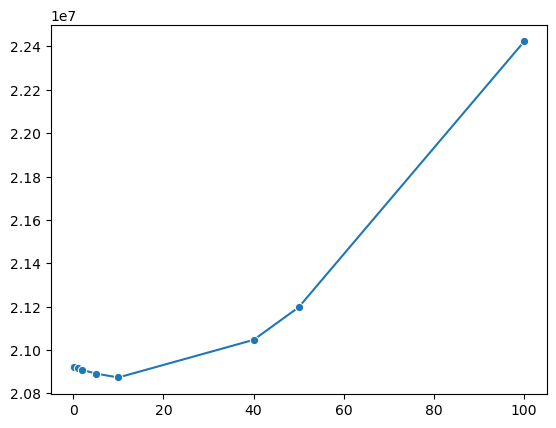

In [16]:
import seaborn as sns
alphas = [0.001, 0.1, 1, 2, 5, 10, 40, 50, 100]
mses = []

for a in alphas:
    lasso_model = Lasso(alpha=a)
    lasso_model.fit(x_train, y_train)
    
    y_pred = lasso_model.predict(x_test)
    
    mse = mean_squared_error(y_test, y_pred)
    print(f"MSE for alpha = {a}: ", mse)
    mses.append(mse)

sns.lineplot(x=alphas, y=mses, marker="o")

In [19]:
from sklearn.linear_model import LassoCV
a = [0.001, 0.1, 1, 2, 5, 10, 40, 50, 100]

lasso_cv_model = LassoCV (
    alphas = a,
    cv=5,
    max_iter=1000,
    random_state=42
)

lasso_cv_model.fit(x_train, y_train)
print("best alpha value: ", lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
print("mse= ", mse)
r2 = r2_score(y_test, y_pred)
print("r2= ", r2)

best alpha value:  0.001
mse=  20922599.87103596
r2=  0.8652317499151699
